In [1]:
import os, glob, zlib, datetime
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import xarray as xr
import regionmask
from shapely.geometry import box, MultiPolygon
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from sklearn.model_selection import LeaveOneGroupOut

import warnings
warnings.filterwarnings("ignore", message="The specified chunks separate the stored chunks")

BASE = "/Users/charan/Desktop/SAI Summer (Updated)"
OUTDIR = "/Users/charan/outputs"

STRATEGY_LABELS = {"0N": 0, "15N_15S": 1, "30N_30S": 2, "60N_60S": 3, "MULTI": 4}
EXTRA_TARGETS = {"1.0": "LOWER-1.0", "gauss_default": "GAUSS-DEFAULT"}   # ARISE removed
MEMBERS = ["001", "002", "003"]
MIN_MONTHS_PER_YEAR = 12
YEARS = list(range(2035, 2070))

REGIONS = {
    "tropical_mean":  dict(lat=(-20, 20), lon=(0, 360)),
    "amazon_basin":   dict(lat=(-15, 5),  lon=(282, 310)),
    "congo_basin":    dict(lat=(-10, 8),  lon=(12, 31)),
    "nino34":         dict(lat=(-5, 5),   lon=(190, 240)),
    "atlantic_mdr":   dict(lat=(5, 20),   lon=(275, 345)),
    "natl_midlat":    dict(lat=(30, 60),  lon=(280, 360)),
    "polar_cap":      dict(lat=(70, 90),  lon=(0, 360)),
    "aleutian_low":   dict(lat=(30, 70),  lon=(140, 240)),
    "se_asia_monsoon": dict(lat=(0, 30), lon=(90, 110)),
}
SEAICE_REGIONS = {
    "arctic":    dict(lat=(65, 90),  lon=(0, 360)),
    "antarctic": dict(lat=(-90, -65), lon=(0, 360)),
}
SEAICE_MONTHS = {"arctic": 9, "antarctic": 3}
VARS = ["TREFHT", "PRECT", "ICEFRAC"]
VAR_REGIONS = {"TREFHT": list(REGIONS), "PRECT": list(REGIONS), "ICEFRAC": list(SEAICE_MONTHS)}
GLOBAL_REGION = {"global": dict(lat=(-90, 90), lon=(0, 360))}
GLOBAL_VARS = ["TREFHT", "PRECT"]

def var_feats(var):
    return [f"{var}_{r}" for r in VAR_REGIONS[var]]

def stable_seed(name):
    return zlib.crc32(name.encode())

feats_all = [f for v in VARS for f in var_feats(v)]
feats_global = [f"{v}_global" for v in GLOBAL_VARS] + var_feats("ICEFRAC")
feats_global_plus_regional = list(dict.fromkeys(feats_global + feats_all))
TRANSFER_FEATURE_SETS = {
    "regional": feats_all,
    "global": feats_global,
    "global_plus_regional": feats_global_plus_regional,
}

In [2]:
# feature extraction
def find_multi_target_file(target_folder, member, var_tag, base=BASE):
    d = os.path.join(base, f"{target_folder}.{member}")
    hits = glob.glob(os.path.join(d, f"*{var_tag}*.nc"))
    assert len(hits) == 1, f"expected exactly 1 file, got {hits} in {d}"
    return hits[0]

def _box_outline(lat_range, lon_range):
    lat0, lat1 = lat_range
    lo, hi = lon_range
    if lo <= hi:
        return box(lo, lat0, hi, lat1)
    return MultiPolygon([box(lo, lat0, 360, lat1), box(0, lat0, hi, lat1)])

def build_regions(region_defs):
    names = list(region_defs.keys())
    outlines = [_box_outline(region_defs[n]["lat"], region_defs[n]["lon"]) for n in names]
    return regionmask.Regions(outlines, names=names, abbrevs=[n[:4] for n in names],
                              name="SAI regions", overlap=True)

def cf_lat_cell_weights(lat_da):
    w = np.cos(np.deg2rad(lat_da.values))
    return xr.DataArray(w, dims="lat", coords={"lat": lat_da["lat"] if "lat" in lat_da.coords else lat_da})

def regional_means_latlon(annual, region_defs):
    regions = build_regions(region_defs)
    mask3d = regions.mask_3D(annual, wrap_lon=360, use_cf=False)
    weights = cf_lat_cell_weights(annual["lat"])
    out = {}
    for i, name in enumerate(regions.names):
        m = mask3d.sel(region=i)
        out[name] = annual.where(m).weighted(weights.fillna(0)).mean(dim=("lat", "lon"), skipna=True)
    return out

def _open_monthly(fpath, varname):
    ds = xr.open_dataset(fpath, chunks={"time": 60})
    if "time_bnds" in ds.variables:
        ds = ds.assign_coords(time=ds["time_bnds"].mean(ds["time_bnds"].dims[-1]))
    else:
        print(f"  [NO time_bnds] {os.path.basename(fpath)} ({varname}) -- shifting time back 15 days")
        ds = ds.assign_coords(time=ds.get_index("time") - datetime.timedelta(days=15))
    return ds, ds[varname]

def annual_mean_region_series(fpath, varname, region_defs):
    ds, da = _open_monthly(fpath, varname)
    annual = da.groupby("time.year").mean("time", skipna=True)
    n_months = da["time"].groupby("time.year").count()
    annual = annual.where(n_months >= MIN_MONTHS_PER_YEAR)
    means = regional_means_latlon(annual, region_defs)
    out = {}
    for rname, rmean in means.items():
        rmean = rmean.compute()
        out[rname] = pd.Series(rmean.values, index=rmean["year"].values).reindex(YEARS)
    ds.close()
    return out

def seaice_month_region_series(fpath, varname="ICEFRAC", seaice_months=SEAICE_MONTHS):
    ds, da = _open_monthly(fpath, varname)
    out = {}
    for rname, month in seaice_months.items():
        da_m = da.isel(time=np.flatnonzero(da["time"].dt.month.values == month))
        monthly = da_m.groupby("time.year").mean("time", skipna=True)
        rmean = regional_means_latlon(monthly, {rname: SEAICE_REGIONS[rname]})[rname].compute()
        out[rname] = pd.Series(rmean.values, index=rmean["year"].values).reindex(YEARS)
    ds.close()
    return out

def build_multi_target_feature_matrix(target_folders, base=BASE, members=MEMBERS):
    region_defs = {**REGIONS, **GLOBAL_REGION}
    rows = []
    for target_id, folder in target_folders.items():
        for mem in members:
            d = {}
            for var in VARS:
                fpath = find_multi_target_file(folder, mem, var, base=base)
                d[var] = (seaice_month_region_series(fpath, var) if var == "ICEFRAC"
                          else annual_mean_region_series(fpath, var, region_defs))
            for year in YEARS:
                row = {"strategy": "MULTI", "label": STRATEGY_LABELS["MULTI"],
                       "member": mem, "year": year, "target": target_id}
                for var in VARS:
                    for rname in d[var]:
                        row[f"{var}_{rname}"] = d[var][rname].loc[year]
                rows.append(row)
            print(f"  extracted MULTI target={target_id} ({folder}).{mem}")
    return pd.DataFrame(rows)

In [3]:
# classifier and null
def _make_pipeline(C, random_state):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=C, max_iter=2000, random_state=random_state)),
    ])

def lomo_transfer_eval(df, df_multi_test, feature_cols, years=YEARS, members=MEMBERS, C=0.1,
                       random_state=0, unpaired_targets=()):
    train_all = df.dropna(subset=feature_cols + ["label"])
    test_all = df_multi_test.dropna(subset=feature_cols + ["label"])
    targets = list(dict.fromkeys(test_all["target"]))
    scores = {t: [] for t in targets}
    pred_parts = []
    for held_out in members:
        train = train_all[train_all["member"] != held_out]
        pipe = _make_pipeline(C, random_state)
        pipe.fit(train[feature_cols].values, train["label"].values)
        for t in targets:
            test = test_all[test_all["target"] == t]
            if t not in unpaired_targets:
                test = test[test["member"] == held_out]
            proba = pipe.predict_proba(test[feature_cols].values)
            col = np.searchsorted(pipe.classes_, test["label"].values)
            test = test.assign(pred=pipe.classes_[proba.argmax(axis=1)],
                               p_true=proba[np.arange(len(test)), col], fold=held_out)
            scores[t].append(test.groupby("year")["p_true"].mean().reindex(years).values)
            pred_parts.append(test[["target", "member", "fold", "year", "label", "pred", "p_true"]])
    curves = {}
    for t in targets:
        fold_arrs = np.array(scores[t], dtype=float)
        curve = pd.DataFrame({"year": years, "mean_acc": np.nanmean(fold_arrs, axis=0),
                              "std_acc": np.nanstd(fold_arrs, axis=0)})
        curve["smooth_acc"] = curve["mean_acc"].rolling(5, center=True, min_periods=1).mean()
        curves[t] = curve
    return curves, pd.concat(pred_parts, ignore_index=True)

def _one_null_permutation_transfer(df, df_multi_test, feature_cols, years, members, C, seed,
                                   unpaired_targets=()):
    rng = np.random.default_rng(seed)
    labels = np.sort(df["label"].unique())
    label_dtype = df["label"].dtype
    dfp, testp = df.copy(), df_multi_test.copy()
    paired = ~testp["target"].isin(unpaired_targets)
    for mem in members:
        mapping = dict(zip(labels, rng.permutation(labels)))
        idx = dfp.index[dfp["member"] == mem]
        dfp.loc[idx, "label"] = dfp.loc[idx, "label"].map(mapping).astype(label_dtype)
        idx = testp.index[paired & (testp["member"] == mem)]
        testp.loc[idx, "label"] = testp.loc[idx, "label"].map(mapping).astype(label_dtype)
    curves, _ = lomo_transfer_eval(dfp, testp, feature_cols, years=years, members=members, C=C,
                                   unpaired_targets=unpaired_targets)
    return np.array([curves[t]["mean_acc"].values for t in curves])

def generate_null_curves_transfer(df, df_multi_test, feature_cols, n_perm=10000, members=MEMBERS,
                                  years=YEARS, C=0.1, seed=0, n_jobs=-1, verbose=0,
                                  unpaired_targets=()):
    sub = df.dropna(subset=feature_cols + ["label"]).copy()
    test = df_multi_test.dropna(subset=feature_cols + ["label"]).copy()
    targets = list(dict.fromkeys(test["target"]))
    child_seeds = np.random.SeedSequence(seed).spawn(n_perm)
    results = np.array(Parallel(n_jobs=n_jobs, backend="loky", verbose=verbose)(
        delayed(_one_null_permutation_transfer)(sub, test, feature_cols, years, members, C,
                                                child_seeds[p], unpaired_targets)
        for p in range(n_perm)
    ))
    return {t: results[:, i, :] for i, t in enumerate(targets)}

def max_stat_band(null_curves, alpha=0.05):
    return np.percentile(np.nanmax(null_curves, axis=1), 100 * (1 - alpha))

def global_fwer_pvalue(real_curve_vals, null_curves):
    per_draw_max = np.nanmax(null_curves, axis=1)
    real_max = np.nanmax(real_curve_vals)
    return (np.sum(per_draw_max >= real_max) + 1) / (len(per_draw_max) + 1)

In [4]:
# test data
df_full = pd.read_csv(os.path.join(OUTDIR, "feature_matrix_with_global.csv"), dtype={"member": str})
df_multi_targets = build_multi_target_feature_matrix(EXTRA_TARGETS)
df_multi_test = pd.concat([df_full[df_full["strategy"] == "MULTI"].assign(target="0.5"),
                           df_multi_targets], ignore_index=True)
print(df_multi_test.groupby("target")["member"].nunique())

saved = pd.read_csv(os.path.join(OUTDIR, "multi_transfer.csv"))
saved["test_target"] = saved["test_target"].astype(str)
saved = saved.set_index(["feature_set", "test_target"])

all_ok = True
for fs_name, feats in TRANSFER_FEATURE_SETS.items():
    print(f"\nFeature set: {fs_name}")
    curves, _ = lomo_transfer_eval(df_full, df_multi_test, feats)
    seed = stable_seed("multi_transfer" if fs_name == "regional" else f"multi_transfer_{fs_name}")
    nulls = generate_null_curves_transfer(df_full, df_multi_test, feats, n_perm=10000, seed=seed)

    for t, curve in curves.items():
        ref = saved.loc[(fs_name, t)]
        real_curve = pd.read_csv(os.path.join(OUTDIR, f"multi_transfer_curve_{fs_name}_{t}.csv"))
        d_curve = np.nanmax(np.abs(curve["mean_acc"].values - real_curve["mean_acc"].values))
        thr = max_stat_band(nulls[t], alpha=0.20)
        p = global_fwer_pvalue(curve["mean_acc"].values, nulls[t])
        ok = (d_curve < 1e-9 and np.isclose(thr, ref["fwer_threshold"], rtol=0, atol=1e-9)
              and np.isclose(p, ref["global_fwer_pvalue_of_peak"], rtol=0, atol=1e-12))
        all_ok &= ok
        print(f"  {t:>14}: curve diff {d_curve:.1e} | threshold {thr:.6f} (saved {ref['fwer_threshold']:.6f}) "
              f"| peak p {p:.5f} (saved {ref['global_fwer_pvalue_of_peak']:.5f}) -> {'MATCH' if ok else 'MISMATCH'}")
        if ok:
            np.save(os.path.join(OUTDIR, f"multi_transfer_nulls_{fs_name}_{t}.npy"), nulls[t])

print("\nAll targets reproduced exactly; null files saved." if all_ok
      else "\nSome targets did not match -- those null files were NOT saved.")

  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-1.0.001.cam.h0.TREFHT.203501-206912.nc (TREFHT) -- shifting time back 15 days
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-1.0.001.cam.h0.PRECT.203501-206912.nc (PRECT) -- shifting time back 15 days
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-1.0.001.cam.h0.ICEFRAC.203501-206912.nc (ICEFRAC) -- shifting time back 15 days
  extracted MULTI target=1.0 (LOWER-1.0).001
  extracted MULTI target=1.0 (LOWER-1.0).002
  extracted MULTI target=1.0 (LOWER-1.0).003
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-DEFAULT.001.cam.h0.TREFHT.203501-206912.nc (TREFHT) -- shifting time back 15 days
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-DEFAULT.001.cam.h0.PRECT.203501-206912.nc (PRECT) -- shifting time back 15 days
  [NO time_

In [5]:
# plot figure
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

STRATEGIES = {"0N": "0N-LOWER-0.5", "15N_15S": "15N_15S-LOWER-0.5", "30N_30S": "30N_30S-LOWER-0.5",
              "60N_60S": "60N_60S-LOWER-0.5", "MULTI": "LOWER-0.5"}
STRATEGY_LABELS = {"0N": 0, "15N_15S": 1, "30N_30S": 2, "60N_60S": 3, "MULTI": 4}
YEARS = list(range(2035, 2070))

INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
SURFACE = "#ffffff"   # pure white background (was "#fcfcfb")
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
STRATEGY_COLORS = dict(zip(STRATEGIES, SERIES))
STRATEGY_NAMES = {"0N": "0N", "15N_15S": "15N+15S", "30N_30S": "30N+30S",
                  "60N_60S": "60N+60S", "MULTI": "MULTI"}

TARGET_NAMES = {"gauss_default": "GAUSS-DEFAULT (1.5 °C)",
                "arise_1.5": "ARISE-SAI-1.5 (1.5 °C)",
                "0.5": "LOWER-0.5 (1.0 °C, training target)",
                "1.0": "LOWER-1.0 (0.5 °C)"}
TARGET_ORDER = ["gauss_default", "0.5", "1.0"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2,
})

FIGDIR = os.path.join(OUTDIR, "figures")
os.makedirs(FIGDIR, exist_ok=True)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{name}.{ext}"), dpi=300, bbox_inches="tight")

def mark_emergence(ax, curve, ey):
    """Marker on the curve at the emergence year, with a guide line and label at the panel foot."""
    y = curve.loc[curve["year"] == ey, "mean_acc"].iloc[0]
    ax.plot([ey, ey], [0, y], color=MUTED, linewidth=1, zorder=1)
    ax.plot(ey, y, "o", ms=8, color=SERIES[0], mec=SURFACE, mew=2, zorder=3)
    ax.annotate(f"emerges {ey}", (ey, 0), xytext=(4, 4), textcoords="offset points",
                fontsize=8, color=INK)

In [6]:
# load saved results
transfer_df = pd.read_csv(os.path.join(OUTDIR, "multi_transfer.csv"))
transfer_df["test_target"] = transfer_df["test_target"].astype(str)
transfer_df = transfer_df[transfer_df["test_target"].isin(TARGET_ORDER)]

transfer_results = {}
for fs_name in ["regional", "global", "global_plus_regional"]:   # same order as cell 36
    curves = {t: pd.read_csv(os.path.join(OUTDIR, f"multi_transfer_curve_{fs_name}_{t}.csv"))
              for t in TARGET_ORDER}
    nulls = {t: np.load(os.path.join(OUTDIR, f"multi_transfer_nulls_{fs_name}_{t}.npy"))
             for t in TARGET_ORDER}
    preds = pd.read_csv(os.path.join(OUTDIR, f"multi_transfer_predictions_{fs_name}.csv"))
    preds["target"] = preds["target"].astype(str)
    preds = preds[preds["target"].isin(TARGET_ORDER)]
    transfer_results[fs_name] = {"curves": curves, "nulls": nulls, "preds": preds}

In [14]:
def plot_transfer_curves(transfer_curves, transfer_nulls, transfer_df, chance=1 / len(STRATEGIES), name_suffix="",
                         axes=None):
    """Predicted probability of MULTI over time at each target, against its permutation null.
    Pass `axes` (a 1 x n array) to draw into an existing figure instead of making and saving a new one."""
    res = transfer_df.set_index("test_target")
    order = [t for t in TARGET_ORDER if t in transfer_curves]
    standalone = axes is None
    if standalone:
        fig, axes = plt.subplots(1, len(order), figsize=(4 * len(order), 3.1), sharey=True, squeeze=False)
    for ax, t in zip(axes[0], order):
        c, r = transfer_curves[t], res.loc[t]
        lo, hi = np.nanpercentile(transfer_nulls[t], [5, 95], axis=0)
        ax.fill_between(c["year"], lo, hi, color=GRID, linewidth=0, label="Null, 5–95%")
        ax.axhline(r["fwer_threshold"], color=INK_2, linestyle="--", linewidth=1,
                   label="FWER threshold (α = 0.20)")
        ax.axhline(chance, color=MUTED, linestyle=":", linewidth=1, label=f"Uninformed ({chance:.2f})")
        ax.plot(c["year"], c["mean_acc"], color=SERIES[0], label="P(MULTI), fold mean")
        if pd.notna(r["fwer_emergence_year"]):
            mark_emergence(ax, c, int(r["fwer_emergence_year"]))
        ax.set_title(f"{TARGET_NAMES[t]}\npeak p = {r['global_fwer_pvalue_of_peak']:.3f}", loc="left")
        ax.set_xlabel("Year")
        ax.set_ylim(0, 1)
    axes[0, 0].set_ylabel("Predicted probability of MULTI")
    axes[0, 0].legend(loc="upper left", fontsize=8)
    if standalone:
        save_fig(fig, f"fig_cross_target_curves{name_suffix}")
        return fig


def plot_transfer_composition(transfer_preds, period=5, name_suffix="", axes=None):
    """What the held-out MULTI runs are classified as, by target and 5-year period.
    Pass `axes` (a 1 x n array) to draw into an existing figure instead of making and saving a new one."""
    label_to_strategy = {v: k for k, v in STRATEGY_LABELS.items()}
    p = transfer_preds.assign(
        period=(transfer_preds["year"] - YEARS[0]) // period * period + YEARS[0],
        predicted=transfer_preds["pred"].map(label_to_strategy))
    order = [t for t in TARGET_ORDER if t in set(p["target"])]
    standalone = axes is None
    if standalone:
        fig, axes = plt.subplots(1, len(order), figsize=(4 * len(order), 3.1), sharey=True, squeeze=False)
    for ax, t in zip(axes[0], order):
        share = (p[p["target"] == t].groupby("period")["predicted"].value_counts(normalize=True)
                 .unstack(fill_value=0).reindex(columns=list(STRATEGIES), fill_value=0))
        bottom = np.zeros(len(share))
        for s in STRATEGIES:
            ax.bar(share.index, share[s], bottom=bottom, width=period * 0.8, color=STRATEGY_COLORS[s],
                   edgecolor=SURFACE, linewidth=1.5, label=STRATEGY_NAMES[s])
            bottom += share[s].values
        ax.set_xticks(share.index, [f"{y}–{str(y + period - 1)[-2:]}" for y in share.index],
                      rotation=45, ha="right")
        ax.grid(axis="x", visible=False)
        ax.set_title(TARGET_NAMES[t], loc="left")
        ax.set_ylim(0, 1)
    axes[0, 0].set_ylabel("Share of held-out MULTI runs")
    handles, labels = axes[0, -1].get_legend_handles_labels()
    axes[0, -1].legend(handles[::-1], labels[::-1], title="Classified as", loc="upper left",
                       bbox_to_anchor=(1.02, 1), fontsize=8, title_fontsize=8)
    if standalone:
        save_fig(fig, f"fig_cross_target_composition{name_suffix}")
        return fig

FEATURE_SET_NAMES = {"regional": "regional features only",
                     "global": "global T, P + polar sea ice",
                     "global_plus_regional": "global + regional features"}

In [17]:
for fs_name, r in transfer_results.items():
    plot_transfer_curves(r["curves"], r["nulls"], transfer_df[transfer_df["feature_set"] == fs_name],
                         name_suffix=f"_{fs_name}")
    plt.close()
    plot_transfer_composition(r["preds"], name_suffix=f"_{fs_name}")
    plt.close()

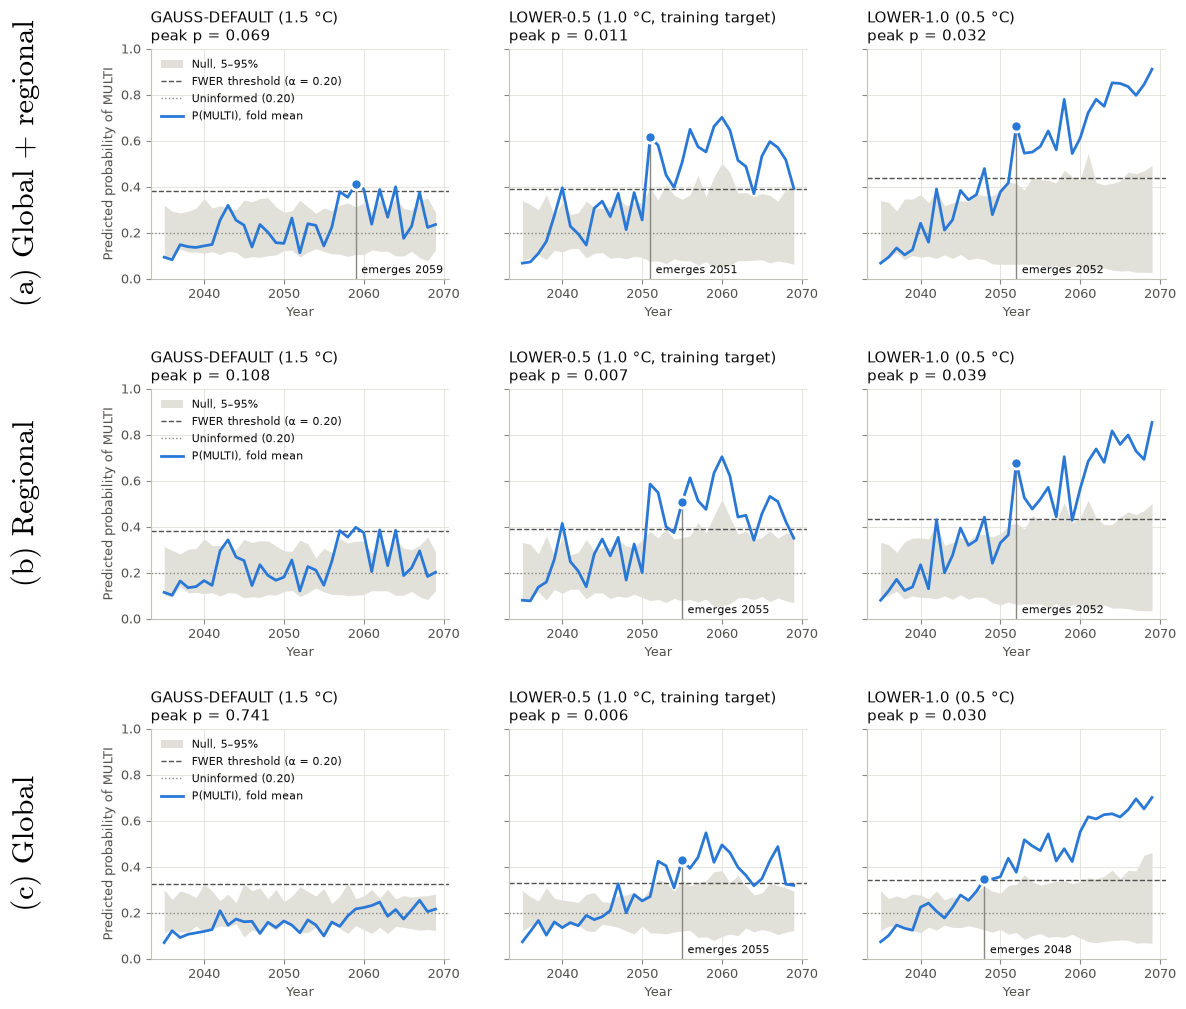

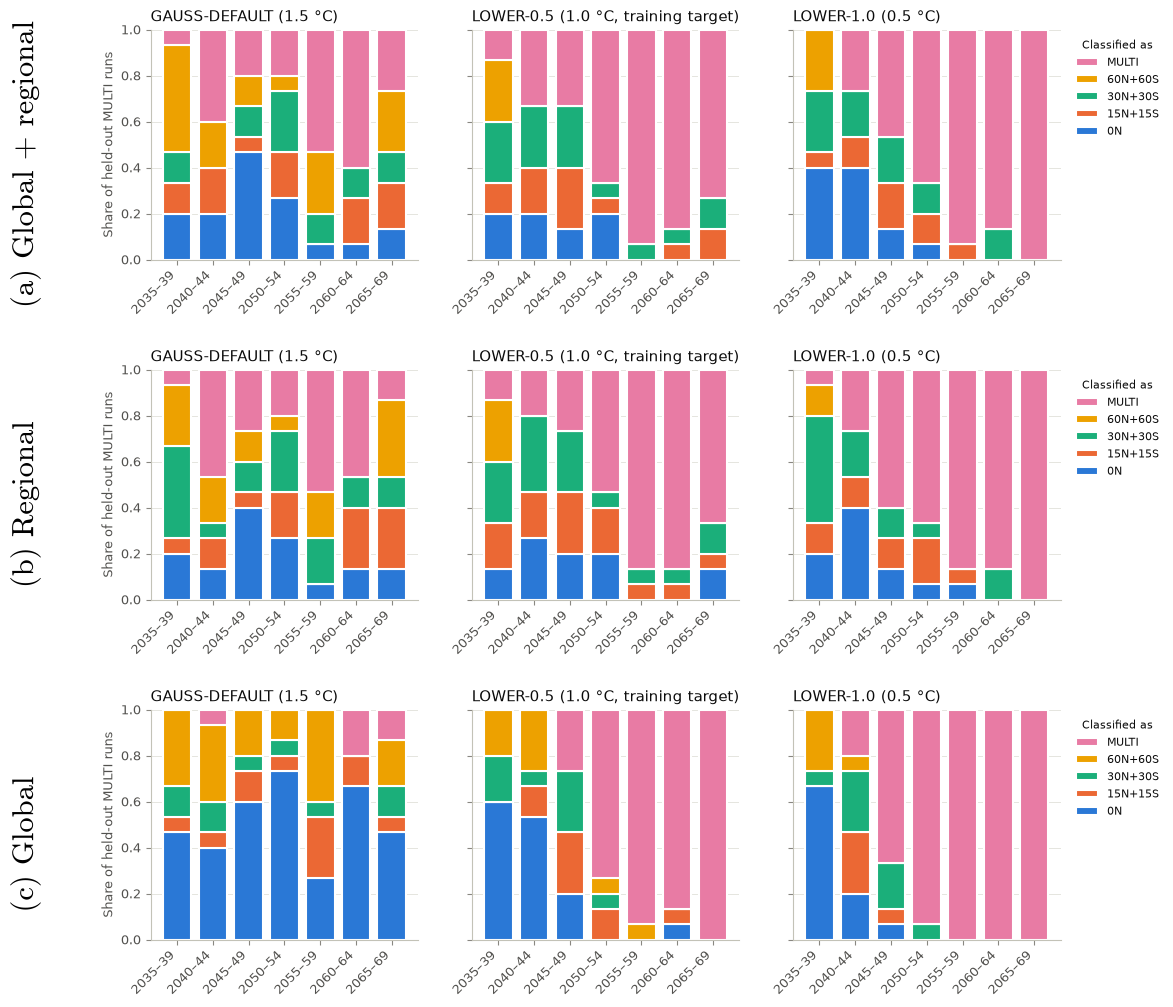

In [21]:
FEATURE_ROWS = [
    ("global_plus_regional", "(a) Global + regional"),
    ("regional",             "(b) Regional"),
    ("global",               "(c) Global"),
]

FIG_W = 12.0
ROW_H = 3.4
LABEL_FONTSIZE = 22

LEFT, WSPACE = 1.55, 0.2
RIGHT = {"curves": 0.3, "composition": 1.35}
TOP = {"curves": 0.55, "composition": 0.35}
BOTTOM = {"curves": 0.55, "composition": 0.75}

def plot_generalization_figure(kind, name):
    """One figure with a row per feature set; kind is "curves" or "composition"."""
    fig = plt.figure(figsize=(FIG_W, ROW_H * len(FEATURE_ROWS)))
    subs = fig.subfigures(len(FEATURE_ROWS), 1)
    for sub, (fs_name, label) in zip(subs, FEATURE_ROWS):
        sub.subplots_adjust(left=LEFT / FIG_W, right=1 - RIGHT[kind] / FIG_W, wspace=WSPACE,
                            top=1 - TOP[kind] / ROW_H, bottom=BOTTOM[kind] / ROW_H)
        axes = sub.subplots(1, len(TARGET_ORDER), sharey=True, squeeze=False)
        r = transfer_results[fs_name]
        if kind == "curves":
            plot_transfer_curves(r["curves"], r["nulls"],
                                 transfer_df[transfer_df["feature_set"] == fs_name], axes=axes)
        else:
            plot_transfer_composition(r["preds"], axes=axes)
        with plt.rc_context({"mathtext.fontset": "cm"}):   # Computer Modern, like the LaTeX labels
            sub.text(0.012, 0.5, r"$\mathrm{" + label.replace("+", "{+}").replace(" ", r"\ ") + "}$",
                     rotation=90, ha="left", va="center", fontsize=LABEL_FONTSIZE, color="black")
    save_fig(fig, name)
    plt.show()
    return fig

plot_generalization_figure("curves", "fig_generalization_prob");
plot_generalization_figure("composition", "fig_generalization_class");

In [10]:
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_seq", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

VAR_NAMES = {"TREFHT": "Temperature", "PRECT": "Precipitation", "ICEFRAC": "Sea-ice fraction"}
REGION_NAMES = {
    "tropical_mean": "Tropical mean", "amazon_basin": "Amazon Basin", "congo_basin": "Congo Basin",
    "nino34": "Niño 3.4", "atlantic_mdr": "Atlantic MDR", "natl_midlat": "N. Atlantic mid-lat.",
    "polar_cap": "Polar cap", "arctic": "Arctic", "antarctic": "Antarctic", "aleutian_low": "Aleutian Low",
    "se_asia_monsoon": "SE Asian monsoon",
}

def lomo_pooled_train_peryear_eval(df, feature_cols, years=YEARS, members=MEMBERS, C=0.1, random_state=0):
    """
    Rotate through 3 folds (hold out one member at a time) using
    sklearn.model_selection.LeaveOneGroupOut (groups = ensemble member).
    """
    sub = df.dropna(subset=feature_cols + ["label"]).copy().reset_index(drop=True)
    X = sub[feature_cols].values
    y = sub["label"].values
    groups = sub["member"].values

    logo = LeaveOneGroupOut()
    acc_per_fold = {}
    for train_idx, test_idx in logo.split(X, y, groups):
        held_out = groups[test_idx][0]
        pipe = _make_pipeline(C, random_state)
        pipe.fit(X[train_idx], y[train_idx])

        test = sub.iloc[test_idx]
        yearly_acc = []
        for year in years:
            tst_y = test[test["year"] == year]
            if len(tst_y) == 0:
                print(f"Notice: No data for member {held_out} in year {year}. Inserting NaN.")
                yearly_acc.append(np.nan)
                continue
            yearly_acc.append(pipe.score(tst_y[feature_cols].values, tst_y["label"].values))
        acc_per_fold[held_out] = yearly_acc

    fold_arrs = np.array([acc_per_fold[m] for m in acc_per_fold])
    curve = pd.DataFrame(
        {"year": years, "mean_acc": np.nanmean(fold_arrs, axis=0), "std_acc": np.nanstd(fold_arrs, axis=0)}
    )
    curve["smooth_acc"] = curve["mean_acc"].rolling(5, center=True, min_periods=1).mean()
    return curve, fold_arrs

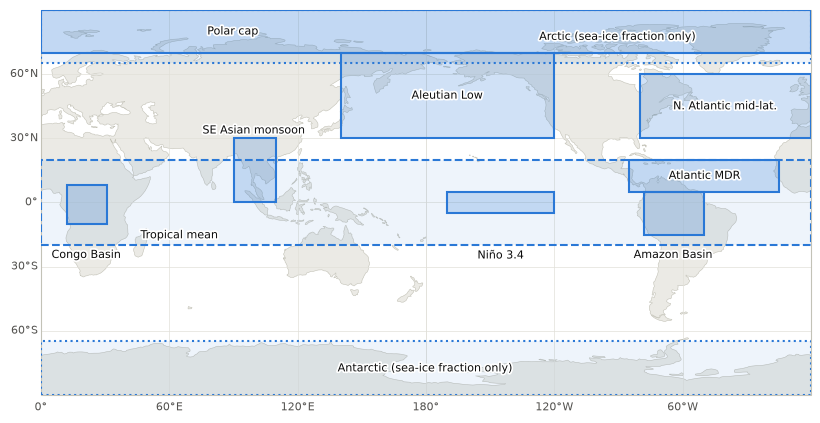

In [11]:
# region map
REGION_LABEL_POS = {
    "tropical_mean": (65, -18, "center", "bottom"),
    "amazon_basin": (296, -22, "center", "top"),
    "congo_basin": (21.5, -22, "center", "top"),
    "nino34": (215, -22, "center", "top"),
    "atlantic_mdr": (310, 12.5, "center", "center"),
    "natl_midlat": (320, 45, "center", "center"),
    "polar_cap": (90, 80, "center", "center"),
    "arctic": (270, 77.5, "center", "center"),
    "antarctic": (180, -77.5, "center", "center"),
    "aleutian_low": (190, 50, "center", "center"),
    "se_asia_monsoon": (100, 31, "center", "bottom"),
}

def plot_region_map(region_defs={**REGIONS, **SEAICE_REGIONS}):
    """Map of the region definitions used to generate regional features"""
    data_crs = ccrs.PlateCarree()
    color = SERIES[0]

    fig = plt.figure(figsize=(10, 5))
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree(central_longitude=180))
    ax.set_extent([0, 359.9, -90, 90], crs=data_crs)
    ax.add_feature(cfeature.LAND, facecolor="#ebeae5", edgecolor="none", zorder=0)
    ax.add_feature(cfeature.COASTLINE, edgecolor=AXIS, linewidth=0.4, zorder=1)
    gl = ax.gridlines(draw_labels=True, color=GRID, linewidth=0.5, xlocs=range(-180, 181, 60),
                      ylocs=range(-90, 91, 30))
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {"color": INK_2, "size": 8}

    for name, d in region_defs.items():
        (lat0, lat1), (lon0, lon1) = d["lat"], d["lon"]
        is_band = name == "tropical_mean"
        is_seaice = name in SEAICE_REGIONS
        ax.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, transform=data_crs,
                               facecolor=color, alpha=0.08 if (is_band or is_seaice) else 0.22, edgecolor="none",
                               zorder=2))
        ax.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, transform=data_crs,
                               fill=False, edgecolor=color, linewidth=1.5,
                               linestyle=":" if is_seaice else ("--" if is_band else "-"), zorder=3))
        lon, lat, ha, va = REGION_LABEL_POS[name]
        label = f"{REGION_NAMES[name]} (sea-ice fraction only)" if is_seaice else REGION_NAMES[name]
        ax.text(lon, lat, label, transform=data_crs, ha=ha, va=va, fontsize=8,
                color=INK, zorder=4, path_effects=[pe.withStroke(linewidth=2.5, foreground=SURFACE)])

    save_fig(fig, "fig_region_map")
    return fig

plot_region_map();

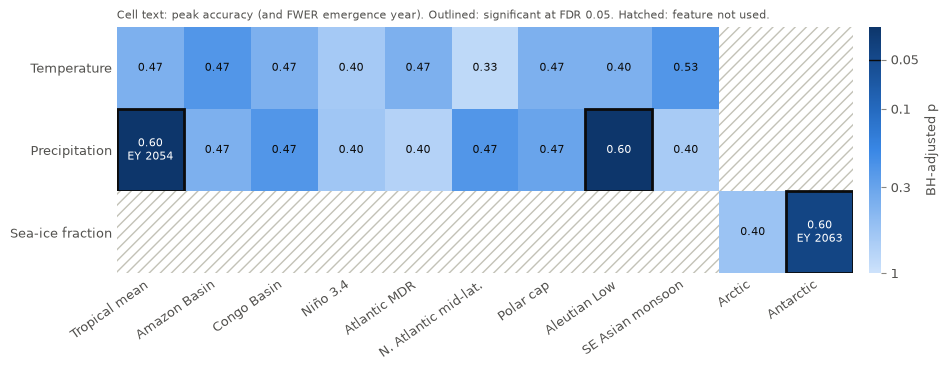

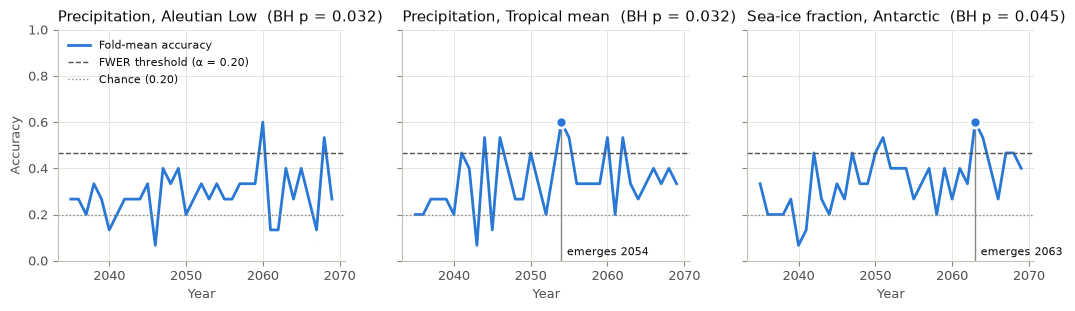

In [12]:
# single region x variable models
emergence_df = pd.read_csv(os.path.join(OUTDIR, "single_region_variable_emergence.csv"))
df = pd.read_csv(os.path.join(OUTDIR, "feature_matrix.csv"), dtype={"member": str})

single_curves = {}
for _, row in emergence_df[emergence_df["significant_fdr05"]].iterrows():
    feat = f"{row['variable']}_{row['region']}"
    single_curves[feat], _ = lomo_pooled_train_peryear_eval(df, [feat])

def plot_single_feature_heatmap(emergence_df):
    """Variable x region grid: colour = BH-adjusted p, text = peak accuracy."""
    regions = list(REGIONS) + list(SEAICE_REGIONS)
    grid = emergence_df.set_index(["variable", "region"])
    logp = np.full((len(VARS), len(regions)), np.nan)
    for i, v in enumerate(VARS):
        for j, r in enumerate(regions):
            if (v, r) in grid.index:
                logp[i, j] = -np.log10(grid.loc[(v, r), "p_fdr_bh"])
    vmax = max(1.5, np.nanmax(logp))

    fig, ax = plt.subplots(figsize=(10, 3.2))
    im = ax.imshow(np.ma.masked_invalid(logp), cmap=BLUE_RAMP, vmin=0, vmax=vmax, aspect="auto")
    ax.grid(False)
    for i, v in enumerate(VARS):
        for j, r in enumerate(regions):
            if (v, r) not in grid.index:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=SURFACE,
                                       edgecolor=AXIS, hatch="///", linewidth=0))
                continue
            row = grid.loc[(v, r)]
            text = f"{row['peak_acc']:.2f}"
            if pd.notna(row["fwer_emergence_year"]):
                text += f"\nEY {int(row['fwer_emergence_year'])}"
            ax.text(j, i, text, ha="center", va="center", fontsize=8,
                    color="#ffffff" if logp[i, j] > 0.65 * vmax else INK)
            if row["significant_fdr05"]:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=INK, linewidth=2))

    ax.set_xticks(range(len(regions)), [REGION_NAMES[r] for r in regions], rotation=35, ha="right")
    ax.set_yticks(range(len(VARS)), [VAR_NAMES[v] for v in VARS])
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    p_ticks = [p for p in (1, 0.3, 0.1, 0.05, 0.01) if -np.log10(p) <= vmax]
    cb.set_ticks([-np.log10(p) for p in p_ticks], labels=[f"{p:g}" for p in p_ticks])
    cb.set_label("BH-adjusted p")
    cb.ax.axhline(-np.log10(0.05), color=INK, linewidth=1)
    cb.outline.set_visible(False)
    ax.set_title("Cell text: peak accuracy (and FWER emergence year). Outlined: significant at FDR 0.05. "
                "Hatched: feature not used.", loc="left", fontsize=8, color=INK_2)
    save_fig(fig, "fig_single_feature_heatmap")
    return fig


def plot_significant_single_curves(emergence_df, single_curves, chance=1 / len(STRATEGIES)):
    """Accuracy over time for the FDR-significant single-feature models."""
    sig = emergence_df[emergence_df["significant_fdr05"]]
    if sig.empty:
        print("No FDR-significant single region x variable models to plot.")
        return None
    fig, axes = plt.subplots(1, len(sig), figsize=(4.2 * len(sig), 3), sharey=True, squeeze=False)
    for ax, (_, row) in zip(axes[0], sig.iterrows()):
        c = single_curves[f"{row['variable']}_{row['region']}"]
        ax.plot(c["year"], c["mean_acc"], color=SERIES[0], label="Fold-mean accuracy")
        ax.axhline(row["fwer_threshold"], color=INK_2, linestyle="--", linewidth=1,
                   label="FWER threshold (α = 0.20)")
        ax.axhline(chance, color=MUTED, linestyle=":", linewidth=1, label=f"Chance ({chance:.2f})")
        if pd.notna(row["fwer_emergence_year"]):
            mark_emergence(ax, c, int(row["fwer_emergence_year"]))
        ax.set_title(f"{VAR_NAMES[row['variable']]}, {REGION_NAMES[row['region']]}  "
                     f"(BH p = {row['p_fdr_bh']:.3f})", loc="left")
        ax.set_xlabel("Year")
        ax.set_ylim(0, 1)
    axes[0, 0].set_ylabel("Accuracy")
    axes[0, 0].legend(loc="upper left", fontsize=8)
    save_fig(fig, "fig_single_feature_significant_curves")
    return fig


plot_single_feature_heatmap(emergence_df);
plot_significant_single_curves(emergence_df, single_curves);

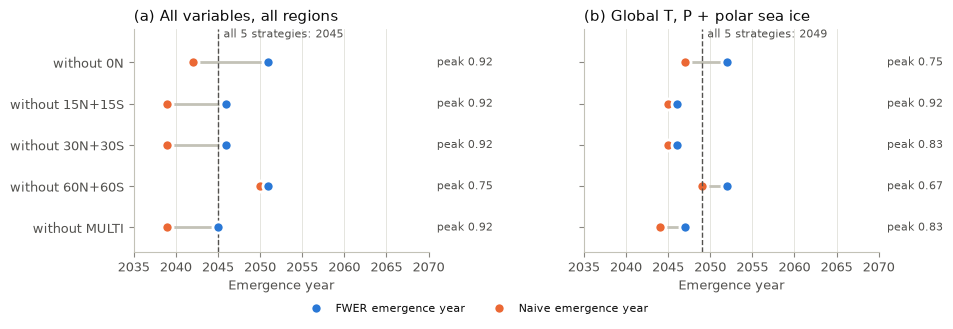

In [13]:
# leave-one-strategy-out
loso_all_df = pd.read_csv(os.path.join(OUTDIR, "leave_one_strategy_out_all_regional.csv"))
loso_global_df = pd.read_csv(os.path.join(OUTDIR, "leave_one_strategy_out_global_only.csv"))
headline_df = pd.read_csv(os.path.join(OUTDIR, "headline_holm_bonferroni_summary.csv"))

def plot_loso_dumbbell(panels):
    """
    Leave-one-strategy-out analysis presented as a dumbbell plot
    """
    strategies = list(STRATEGIES)[::-1]
    fig, axes = plt.subplots(1, len(panels), figsize=(4.8 * len(panels), 3.1), sharey=True, squeeze=False)
    for ax, (title, d, full_ey) in zip(axes[0], panels):
        d = d.set_index("strategy_left_out")
        for y, s in enumerate(strategies):
            naive, fwer = d.loc[s, "naive_emergence_year"], d.loc[s, "fwer_emergence_year"]
            if pd.notna(naive) and pd.notna(fwer):
                ax.plot([naive, fwer], [y, y], color=AXIS, linewidth=2, zorder=1)
            if pd.notna(naive):
                ax.plot(naive, y, "o", ms=8, color=SERIES[1], mec=SURFACE, mew=2, zorder=2)
            if pd.notna(fwer):
                ax.plot(fwer, y, "o", ms=8, color=SERIES[0], mec=SURFACE, mew=2, zorder=3)
            ax.annotate(f"peak {d.loc[s, 'peak_acc']:.2f}", (1, y), xycoords=("axes fraction", "data"),
                        xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK_2)
        if full_ey is not None and pd.notna(full_ey):
            ax.axvline(full_ey, color=INK_2, linestyle="--", linewidth=1)
            ax.annotate(f"all 5 strategies: {int(full_ey)}", (full_ey, len(strategies) - 0.4),
                        xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK_2)
        ax.set_yticks(range(len(strategies)), [f"without {STRATEGY_NAMES[s]}" for s in strategies])
        ax.set_ylim(-0.6, len(strategies) - 0.2)
        ax.set_xlim(YEARS[0], YEARS[-1] + 1)
        ax.set_xlabel("Emergence year")
        ax.grid(axis="y", visible=False)
        ax.set_title(title, loc="left")
    handles = [plt.Line2D([], [], marker="o", ms=8, color=c, mec=SURFACE, mew=2, linestyle="")
               for c in (SERIES[0], SERIES[1])]
    fig.legend(handles, ["FWER emergence year", "Naive emergence year"], loc="lower center",
               ncol=2, bbox_to_anchor=(0.5, -0.06), fontsize=8)
    fig.tight_layout(w_pad=6)
    save_fig(fig, "fig_leave_one_strategy_out")
    return fig;


headline_ey = headline_df.set_index("test")["fwer_emergence_year"]
plot_loso_dumbbell([
    ("(a) All variables, all regions", loso_all_df, headline_ey.get("ALL (regional)")),
    ("(b) Global T, P + polar sea ice", loso_global_df, headline_ey.get("global_only")),
]);